##Лабораторная работа №3. Кластеризация


Цель работы: изучение алгоритмов кластеризации, приобретение навыков оценки качества разбиения данных на кластеры и интерпретации результатов.

Постановка задачи:

1. Загрузить датасет для задачи кластеризации / классификации (например, с платформы Kaggle). Провести дескриптивный анализ данных.

2. Выполнить стандартизацию / нормализацию числовых признаков. Обосновать выбор метода масштабирования. Построить матрицу диаграмм рассеивания для визуальной оценки структуры данных, предположительного количества кластеров и типа кластерной структуры. Аргументировать выбор методов кластеризации на основе формы, размера и плотности кластеров.

3. Реализовать кластеризацию методами K-means (K-средних) и DBSCAN;

4. Рассчитать метрики качества для обоих методов: внутренние и внешние. Оценить расстояние между кластерами, внутрикластерные расстояния, компактность кластеров, центры кластеров.

5. Исследовать влияние параметров одного из методов на качество кластеризации.

6. Визуализировать полученные кластеры в пространстве признаков (использовать PCA для снижения размерности при необходимости).

# Описание датасета

### Описание датасета и его размерность
Для выполнения работы был выбран датасет Palmer Penguins (Пингвины Палмера), содержащий биометрические измерения 344 пингвинов.

Размерность: 344 строки (объекта) и 7 столбцов (признаков).

Типы признаков: 4 числовых признака с плавающей точкой (culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g) и 3 категориальных (species, island, sex).

# Необходимые импорты

In [1]:
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer

from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering

from sklearn.decomposition import PCA

from sklearn.metrics import (
    silhouette_score, silhouette_samples,
    calinski_harabasz_score, davies_bouldin_score,
    rand_score, adjusted_rand_score
)

from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.stats import zscore

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)
!wget -O penguins_size.csv https://raw.githubusercontent.com/Turbonik/AILab1/main/penguins_size.csv


--2026-11-25 09:47:24--  https://raw.githubusercontent.com/Turbonik/AILab1/main/penguins_size.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 13519 (13K) [text/plain]
Saving to: ‘penguins_size.csv’

penguins_size.csv   100%[===================>]  13.20K  --.-KB/s    in 0s      

2026-11-25 09:47:25 (29.3 MB/s) - ‘penguins_size.csv’ saved [13519/13519]



#Дискриптивный анализ

=== 1. Первые 5 строк ===


,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE



=== 2. Размерность ===
Строк: 344, Столбцов: 7

=== 3. Типы данных и пропуски ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB
None

=== 4. Базовая статистика ===


,count,mean,std,min,25%,50%,75%,max
culmen_length_mm,342.0,43.921930,5.459584,32.1,39.225,44.45,48.5,59.6
culmen_depth_mm,342.0,17.151170,1.974793,13.1,15.600,17.30,18.7,21.5
flipper_length_mm,342.0,200.915205,14.061714,172.0,190.000,197.00,213.0,231.0
body_mass_g,342.0,4201.754386,801.954536,2700.0,3550.000,4050.00,4750.0,6300.0



=== 5. Гистограммы ===


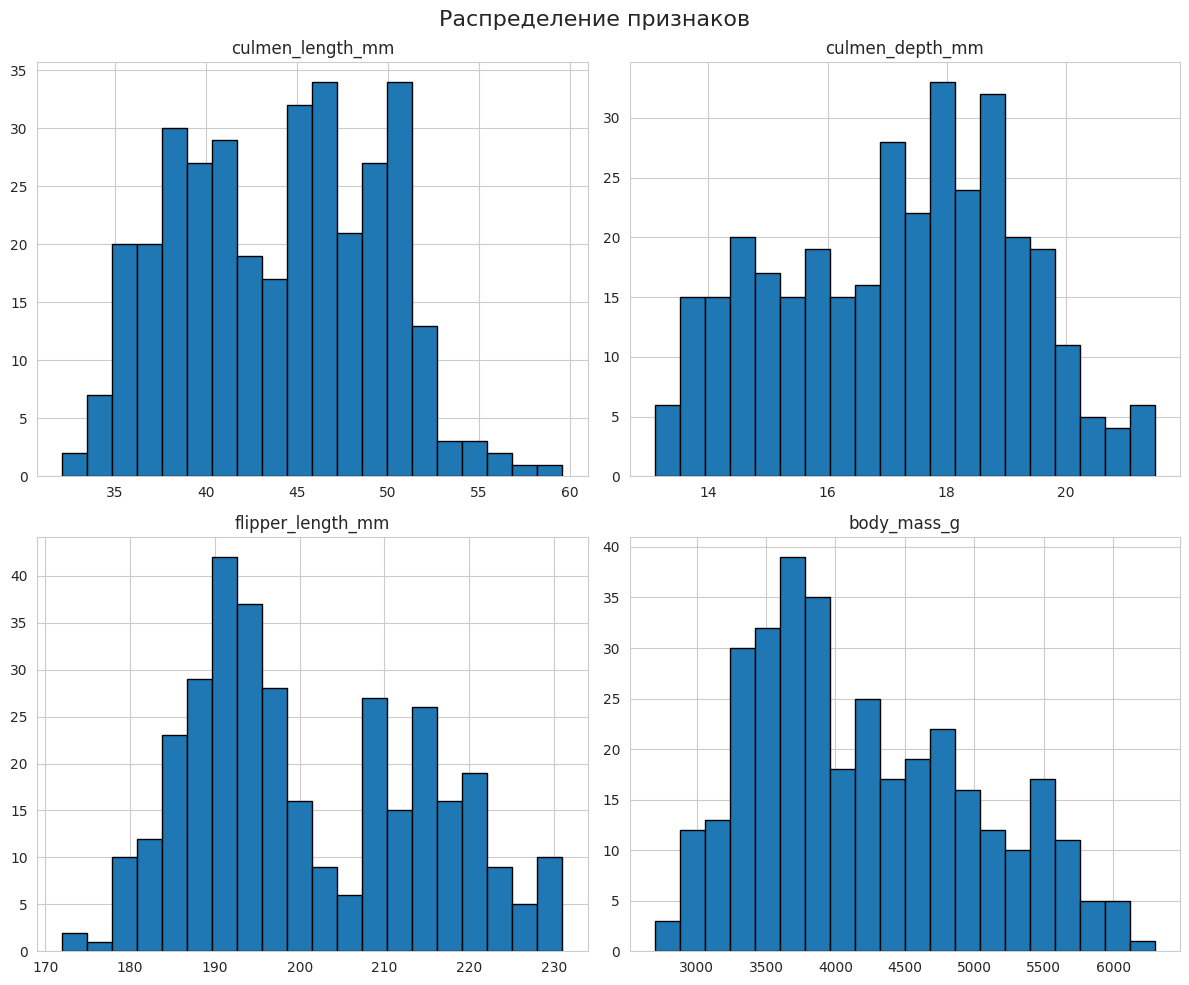

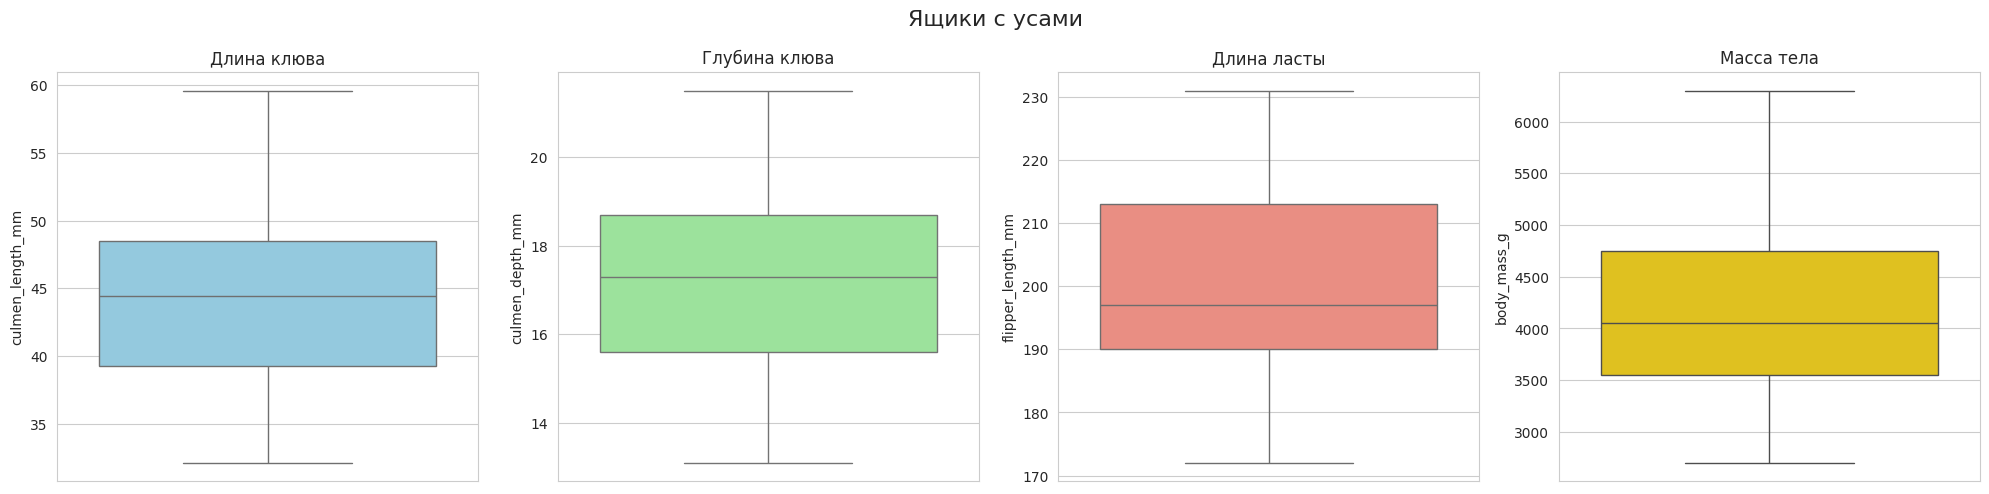

In [2]:
df = pd.read_csv("penguins_size.csv")

print("=== 1. Первые 5 строк ===")
display(df.head())

print("\n=== 2. Размерность ===")
print(f"Строк: {df.shape[0]}, Столбцов: {df.shape[1]}")

print("\n=== 3. Типы данных и пропуски ===")
print(df.info())

print("\n=== 4. Базовая статистика ===")
display(df.describe().T)

print("\n=== 5. Гистограммы ===")
df.hist(figsize=(12, 10), bins=20, edgecolor='black')
plt.suptitle('Распределение признаков', fontsize=16)
plt.tight_layout()
plt.show()


fig, axes = plt.subplots(1, 4, figsize=(20, 5))

sns.boxplot(y=df['culmen_length_mm'], ax=axes[0], color='skyblue')
axes[0].set_title('Длина клюва')

sns.boxplot(y=df['culmen_depth_mm'], ax=axes[1], color='lightgreen')
axes[1].set_title('Глубина клюва')

sns.boxplot(y=df['flipper_length_mm'], ax=axes[2], color='salmon')
axes[2].set_title('Длина ласты')

sns.boxplot(y=df['body_mass_g'], ax=axes[3], color='gold')
axes[3].set_title('Масса тела')

plt.suptitle('Ящики с усами', fontsize=16)
plt.tight_layout()
plt.show()

 # Анализ распределения признаков

Для визуальной оценки формы распределения признаков были построены гистограммы. Анализ графиков позволяет сделать следующие выводы:

Ни один из четырех числовых признаков не подчиняется нормальному закону распределения,

Признаки culmen_length_mm (длина клюва) и body_mass_g (масса тела) имеют ярко выраженную бимодальную структуру.

Распределение признака flipper_length_mm (длина ласты) имеет левостороннюю асимметрию, а culmen_depth_mm (глубина клюва) — правостороннюю.

Вывод: Так как распределения не являются нормальными, для кластеризации целесообразно использовать непараметрические методы (K-means, DBSCAN), не требующие нормальности данных.

In [3]:

X = df[['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']]
y_true = df['species']

imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)
X_imputed_df = pd.DataFrame(X_imputed, columns=X.columns)

print("\nПропуски в X после обработки:")
print(X_imputed_df.isnull().sum())

display(X_imputed_df.head())


Пропуски в X после обработки:
culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
dtype: int64


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
0,39.10,18.7,181.0,3750.0
1,39.50,17.4,186.0,3800.0
2,40.30,18.0,195.0,3250.0
3,44.45,17.3,197.0,4050.0
4,36.70,19.3,193.0,3450.0


#Анализ пропусков

С помощью df.info() было выявлено наличие пропусков:

В числовых признаках (размеры) по 2 пропуска (342 значения из 344).

В категориальном признаке sex — 10 пропусков.
Обработка: Числовые пропуски были заполнены медианой с помощью SimpleImputer(strategy='median'). Категориальные признаки (species, island, sex) были исключены из матрицы признаков X.

species (вид): Исключен, так как является целевой переменной (меткой класса).Колонка сохранена в отдельной переменной y_true для последующего расчета внешних метрик.

island (остров обитания) и sex (пол): Исключены, так как являются категориальными признаками. Методы K-means и DBSCAN основаны на вычислении Евклидова расстояния между числовыми векторами. Они не умеют вычислять расстояние между значениями «Female» и «Male» или «Torgersen» и «Biscoe».

Если перевести пол или остров в числа (0 и 1), алгоритм будет воспринимать это как геометрическую координату, равную по весу размеру клюва. Это создаст искусственные «разрывы» в пространстве и исказит кластеры, которые должны строиться на основе физических размеров. Так как цель — кластеризация по биометрии (размерам), эти категориальные признаки удаляются.

#Нормализация и диаграммы рассеивания

Результаты масштабирования
      culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g
mean              -0.0              0.0                0.0          0.0
std                1.0              1.0                1.0          1.0


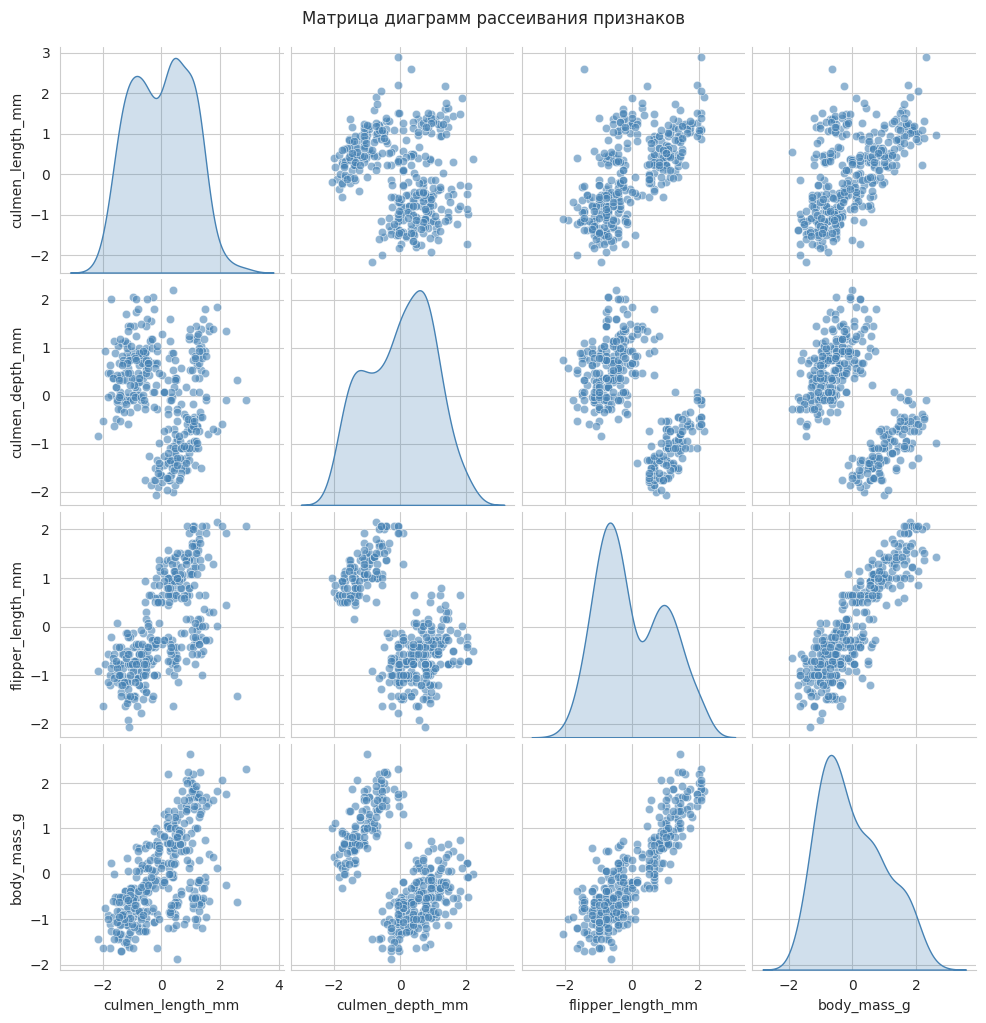

In [6]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed_df)
X_scaled_df = pd.DataFrame(X_scaled, columns=X_imputed_df.columns)

print("Результаты масштабирования")
print(X_scaled_df.describe().loc[['mean', 'std']].round(2))

sns.pairplot(
    X_scaled_df,
    diag_kind='kde',
    plot_kws={'alpha': 0.6, 'color': 'steelblue'},
    diag_kws={'color': 'steelblue'}
)
plt.suptitle('Матрица диаграмм рассеивания признаков', y=1.02)
plt.show()

### Анализ матрицы диаграмм рассеивания

Перед построением матрицы диаграмм рассеивания была выполнена **нормализация (стандартизация)** числовых признаков с помощью `StandardScaler`. Это позволило привести все признаки (измеряемые в миллиметрах и граммах) к единому масштабу.

**1. Визуальная оценка структуры данных:**
Анализируя диаграммы рассеивания, можно сделать следующие выводы:
*   **Отсутствие равномерности:** Точки распределены неравномерно. Нет хаотичного разброса по всему пространству, что говорит о наличии скрытой структуры.
*   **Форма и плотность:** На графиках четко прослеживаются плотные сгустки («облака») точек. Некоторые из них имеют форму, близкую к **кругам/эллипсам** (например, при сравнении `culmen_length_mm` и `culmen_depth_mm`). Другие пары признаков образуют вытянутые **«ленты»** (например, `flipper_length_mm` и `body_mass_g`), что объясняется сильной корреляцией этих признаков.
*   **Предположительное количество кластеров:** В двумерных проекциях визуально выделяются как минимум 2-3 крупных изолированных сгустка. Исходя из этого, можно предположить наличие **2 или 3 кластеров**.

**2. Аргументация выбора методов кластеризации:**

*   **K-means:**
    Наличие четких, плотных и изолированных «круглых» или эллиптических сгустков является идеальной предпосылкой для K-means. Мы предполагаем, что центры этих сгустков будут устойчивыми.
    
*   **DBSCAN:**
    Хотя структура содержит четкие ядра, на графиках также видны вытянутые «ленты» и разреженные области между основными сгустками. Кроме того, в данных присутствуют единичные точки (выбросы), которые могут быть далеко от основных масс. K-means будет «тянуть» центры к этим выбросам. **DBSCAN** же, будучи плотностным алгоритмом, сможет выделить эти вытянутые структуры (он не ограничен формой шара) и автоматически пометит разреженные точки на границах или вдали от сгустков как шум, не искажая общую картину.
